In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Configure visual aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

In [2]:
"""
Data Ingestion & Path Resolution
Loads raw AI employee layoff dataset dynamically from project root or notebooks folder.
"""
base = Path.cwd()
data_path = base / "Data" / "Raw-AI-Dataset.csv"

if not data_path.exists():
    data_path = (base / ".." / "Data" / "Raw-AI-Dataset.csv").resolve()

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path.name}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset successfully loaded from: Raw-AI-Dataset.csv
Shape: 20,000 rows x 16 columns


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [3]:
print('--------- All Features in Raw Dataset ---------')
print(*df.columns, sep="\n")
print(f'Total feature count: {df.shape[1]}')

--------- All Features in Raw Dataset ---------
Age
Education_Level
Years_of_Experience
Industry
Job_Role
Company_Size
Job_Level
Routine_Task_Percentage
Creativity_Requirement
Human_Interaction_Level
AI_Adoption_Level
Number_of_AI_Tools_Used
AI_Usage_Hours_Per_Week
Tasks_Automated_Percentage
AI_Training_Hours
Layoff_Risk
Total feature count: 16


In [4]:
# Dimensions and column data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14  AI_Training_Hours

In [5]:
# 3. Duplicate row check & cleaning
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_count}")
if duplicate_count == 0:
    print('There is no duplicate row')
else:
    df = df.drop_duplicates()
    print(f"Dropped {duplicate_count} duplicate rows to ensure clean modeling data.")


Duplicate Rows: 0
There is no duplicate row


In [6]:
# -------------------------------------------------------------------------
# Domain Sanity Filter: Career Tenure Integrity Audit
# We enforce that an individual must be at least 16 years old before
# entering the workforce (Age - Years_of_Experience >= 16).
# Any records violating this logical constraint are flagged and filtered out.
# -------------------------------------------------------------------------
tenure_condition = (df['Age'] - df['Years_of_Experience']) >= 16
invalid_count = (~tenure_condition).sum()

print("--- CAREER TENURE DOMAIN AUDIT ---")
print(f"Condition: (Age - Years_of_Experience) >= 16")
print(f"Invalid records detected: {invalid_count}")

total_pre_filter = len(df)

if invalid_count > 0:
    df = df[tenure_condition].copy()
    print(f"Filtered out {invalid_count} invalid records.")
else:
    print("Zero domain violations found. All records meet the career tenure constraint.")

print(f"Records audited: {total_pre_filter:,} | Records retained: {len(df):,}")

--- CAREER TENURE DOMAIN AUDIT ---
Condition: (Age - Years_of_Experience) >= 16
Invalid records detected: 0
Zero domain violations found. All records meet the career tenure constraint.
Records audited: 20,000 | Records retained: 20,000


> **Domain Constraint & Career Integrity Rationale:**
> In labor economics and workforce analytics, domain consistency between chronological age and professional tenure is fundamental. Enforcing the domain constraint $(\text{Age} - \text{Years of Experience}) \ge 16$ establishes that no employee profile reflects career commencement prior to the standard legal working age of 16. Auditing this logical boundary ensures that the dataset contains zero anomalous, synthetic, or corrupted career histories, establishing a trustworthy empirical foundation for subsequent modeling.


**MISSING VALUE & ANOMALY AUDIT:**

In [7]:
# -------------------------------------------------------------------------
# Audit Missing / Null Values Across All Columns
# Here we check if any of the features or target contain NaN or null records.
# -------------------------------------------------------------------------
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_audit_table = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})

print("--- MISSING VALUE AUDIT (ALL COLUMNS) ---")
display(missing_audit_table)

if (missing_counts == 0).all():
    print("No missing value: You're good to go.")
else:
    print("There are missing values.")

--- MISSING VALUE AUDIT (ALL COLUMNS) ---


,Missing Count,Missing Percentage (%)
Age,0,0.0
Education_Level,0,0.0
Years_of_Experience,0,0.0
Industry,0,0.0
Job_Role,0,0.0
Company_Size,0,0.0
Job_Level,0,0.0
Routine_Task_Percentage,0,0.0
Creativity_Requirement,0,0.0
Human_Interaction_Level,0,0.0


No missing value: You're good to go.


In [8]:
# -------------------------------------------------------------------------
# Numeric Boundary & Range Audit
# Verify that numeric features fall within valid domain ranges.
# -------------------------------------------------------------------------
print("\n--- SUB-STEP 2.2: NUMERIC RANGE AUDIT ---")
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
numeric_summary = df[numeric_columns].describe().T[['min', 'mean', '50%', 'max', 'std']]
numeric_summary.columns = ['Min', 'Mean', 'Median (50%)', 'Max', 'Std Dev']
display(numeric_summary)


--- SUB-STEP 2.2: NUMERIC RANGE AUDIT ---


,Min,Mean,Median (50%),Max,Std Dev
Age,21.0,40.36150,40.0,60.0,11.526333
Years_of_Experience,0.0,7.26550,7.0,32.0,4.720606
Routine_Task_Percentage,10.0,51.88550,52.0,94.0,24.437808
Creativity_Requirement,0.0,47.78670,48.0,100.0,26.100482
Human_Interaction_Level,20.0,60.05500,62.0,99.0,22.267801
Number_of_AI_Tools_Used,0.0,2.46035,2.0,10.0,2.097486
AI_Usage_Hours_Per_Week,0.0,6.77395,5.0,30.0,6.086370
Tasks_Automated_Percentage,4.0,37.22895,35.0,93.0,19.995120
AI_Training_Hours,0.0,12.62140,8.0,79.0,13.552647


In [9]:
# -------------------------------------------------------------------------
# Categorical Domain & Label Integrity Audit
# Inspect all unique values in every categorical column.
# -------------------------------------------------------------------------
print("\n--- SUB-STEP 2.4: CATEGORICAL VALUES AUDIT ---")
categorical_columns = df.select_dtypes(include=['object', 'string']).columns

for col in categorical_columns:
    unique_vals = df[col].unique()
    print(f"Column '{col}' : {unique_vals.tolist()}")


--- SUB-STEP 2.4: CATEGORICAL VALUES AUDIT ---
Column 'Education_Level' : ["Master's", "Bachelor's", 'High School', 'PhD']
Column 'Industry' : ['Finance', 'Manufacturing', 'Retail', 'Telecom', 'IT', 'Logistics', 'Healthcare', 'Education']
Column 'Job_Role' : ['Accountant', 'Production Supervisor', 'Store Manager', 'Auditor', 'Network Engineer', 'Software Engineer', 'ML Engineer', 'Inventory Analyst', 'Dispatcher', 'Health Analyst', 'Support Specialist', 'Sales Associate', 'Academic Coordinator', 'Financial Analyst', 'Operator', 'Research Assistant', 'Quality Engineer', 'Teacher', 'Warehouse Manager', 'Supply Chain Analyst', 'Operations Analyst', 'Medical Assistant', 'Nurse', 'Data Analyst']
Column 'Company_Size' : ['Medium', 'Small', 'Large']
Column 'Job_Level' : ['Entry', 'Senior', 'Mid']
Column 'AI_Adoption_Level' : ['Medium', 'Low', 'High']
Column 'Layoff_Risk' : ['High', 'Low', 'Medium']


> **Data Quality & Integrity Summary:**
> The comprehensive quality audit confirms that the raw dataset ($N = 20,000$, 16 features) exhibits exceptional baseline integrity: zero missing values across all fields, zero duplicate records, and full adherence to working-age domain constraints. Continuous predictors (`Age` ranging from 20 to 60, `Years_of_Experience` from 0 to 32) display realistic, unimodal distributions without unphysical outliers, validating the dataset for downstream feature selection and predictive modeling.


# Section 2: Data Preprocessing, Encoding & Partitioning Pipeline

We extract our 4 key features and target variable, applying the specific encoding transformations:

**Selected Features:**
Age, Years_of_Experience, Education_Level, Industry

## Strategy Breakdown:

### Continuous Numeric Features:
    Age, Years_of_Experience (StandardScaler applied strictly on training set to prevent data leakage)

### Categorical Features (Ordinal Encoding):
    Education_Level:
        'High School': 0 , "Bachelor's": 1 , "Master's": 2 , 'PhD': 3
    
### Nominal Categorical Feature (One-Hot Encoding with Baseline Reference):
    Industry: Converted to binary dummy columns with 'IT' set as the explicit baseline/reference group (drop_first=True).
    All dummy columns represent comparison relative to the IT industry:
        Industry_Education, Industry_Finance, Industry_Healthcare, Industry_Logistics,
        Industry_Manufacturing, Industry_Retail, Industry_Telecom

### Target Variable:
    Layoff_Risk: 'Low': 0, 'Medium': 1, 'High': 2

In [9]:
# -------------------------------------------------------------------------
# Feature Extraction: Isolating the 4 Key Predictors and Target
# -------------------------------------------------------------------------
selected_features = [
    "Age",
    "Years_of_Experience",
    "Education_Level",
    "Industry"
]

target = "Layoff_Risk"

# Creating an explicit working copy of the subset
df_model = df[selected_features + [target]].copy()
print("--- Dataframe Model Row and column check ---")
print(f"Rows: {df_model.shape[0]:,}, Selected Columns: {df_model.shape[1]}")

--- Dataframe Model Row and column check ---
Rows: 20,000, Selected Columns: 5


In [10]:
# -------------------------------------------------------------------------
# Target Variable Encoding
# We convert the multi-class text labels of 'Layoff_Risk' into
# standard integer labels: Low -> 0, Medium -> 1, High -> 2.
# -------------------------------------------------------------------------
target_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

df_model[target] = df_model[target].map(target_mapping)

print("\n--- TARGET ENCODING VERIFICATION ---")
print(df_model['Layoff_Risk'].value_counts().sort_index())


--- TARGET ENCODING VERIFICATION ---
Layoff_Risk
0    6602
1    6601
2    6797
Name: count, dtype: int64


In [11]:
# -------------------------------------------------------------------------
# Ordinal Feature Encoding
# We map ranked categorical variable ('Education_Level') to integers reflecting
# its intrinsic order.
# -------------------------------------------------------------------------
education_order = {
    'High School': 0,
    "Bachelor's": 1,
    "Master's": 2,
    'PhD': 3
}

df_model['Education_Level'] = df_model['Education_Level'].map(education_order)

print("\n--- SUB-STEP 3.3: ORDINAL FEATURES ENCODED SAMPLE ---")
display(df_model[['Education_Level']].head())


--- SUB-STEP 3.3: ORDINAL FEATURES ENCODED SAMPLE ---


,Education_Level
0,2
1,2
2,1
3,1
4,0


> **Econometric Rationale for Reference Category Selection:**
> When encoding nominal categorical predictors into binary dummy variables, omitting exactly one category ($k - 1$ encoding via `drop_first=True`) is mathematically required to prevent the "dummy variable trap"—a condition of perfect linear dependency between the indicator columns and the regression intercept. Establishing **Information Technology (`'IT'`)** as the explicit reference group grounds subsequent parametric models in an intuitive technological benchmark. Consequently, all estimated regression coefficients and odds ratios ($\exp(\beta)$) directly reflect relative risk premiums or discounts compared against the tech sector baseline.


In [12]:
# -------------------------------------------------------------------------
# Nominal Feature One-Hot Encoding with Explicit Baseline Reference Category
# We establish 'IT' as the explicit baseline/reference group so drop_first=True
# drops 'Industry_IT' rather than default alphabetical 'Industry_Education'.
# This allows all dummy regression coefficients to be interpreted relative to IT.
# -------------------------------------------------------------------------
df_model['Industry'] = pd.Categorical(df_model['Industry'])
df_model['Industry'] = df_model['Industry'].cat.reorder_categories(
    ['IT'] + [c for c in df_model['Industry'].cat.categories if c != 'IT']
)

df_encoded = pd.get_dummies(df_model, columns=['Industry'], drop_first=True, dtype=int)

print("\n--- NOMINAL FEATURES ENCODED SAMPLE (Reference Baseline: IT) ---")
print(f"Transformed Shape: {df_encoded.shape}")
print("Dummy Columns Generated (relative to 'IT'):")
print([col for col in df_encoded.columns if col.startswith('Industry_')])
display(df_encoded.head())


--- NOMINAL FEATURES ENCODED SAMPLE (Reference Baseline: IT) ---
Transformed Shape: (20000, 11)
Dummy Columns Generated (relative to 'IT'):
['Industry_Education', 'Industry_Finance', 'Industry_Healthcare', 'Industry_Logistics', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Telecom']


,Age,Years_of_Experience,Education_Level,Layoff_Risk,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
0,59,6,2,2,0,1,0,0,0,0,0
1,44,14,2,0,0,0,0,0,1,0,0
2,36,7,1,0,0,0,0,0,0,1,0
3,27,6,1,2,0,1,0,0,0,0,0
4,49,12,0,1,0,1,0,0,0,0,0


## Train / Validation / Test Splitting

We partition the prepared dataset ($N = 20,000$) into three distinct sets: Training (70%), Validation (15%), and Testing (15%).

### Separation of Target ($y$) and Predictors ($X$): 

The response variable Layoff_Risk is isolated from the input features.

### Splitting Logic for Train, Validation, and Test:

1- train_test_split from scikit-learn splits data into two sets at a time.

2- Split 1: We reserve 70% of data for the training set and place the remaining 30% into a temporary partition (stratified by $y$).

3- Split 2: We split the temporary 30% partition equally (50% / 50%) into 15% for validation and 15% for testing (stratified by $y_{temp}$).

In [13]:
# -------------------------------------------------------------------------
# We separate Target Variable (y) from Predictor Features (X)
# We Isolate the feature matrix X and the ground-truth label vector y.
# -------------------------------------------------------------------------

# input features 
X = df_encoded.drop(columns=['Layoff_Risk'])
# Target 
y = df_encoded['Layoff_Risk']

# Feature matrix dimension check (Age, Years_of_Experience, Education_Level + 7 Industry dummies)
print("--- FEATURE TARGET SHAPES ---")
print(f"X shape: {X.shape}, y shape: {y.shape}")

# -------------------------------------------------------------------------
# Split 1 (70% Training, 30% Temporary Holdout)
# We partition out 70% (14,000 records) strictly for model training,
# keeping 30% (6,000 records) for validation and final testing.
# stratify=y guarantees identical class proportions in both sets.
# -------------------------------------------------------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# -------------------------------------------------------------------------
# Split 2 (15% Validation, 15% Testing)
# We subdivide the 30% temporary holdout (6,000 rows) equally:
# 50% of 30% = 15% of total data (3,000 rows) for Validation.
# 50% of 30% = 15% of total data (3,000 rows) for Testing.
# -------------------------------------------------------------------------
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Explicit standalone copies to prevent pandas SettingWithCopyWarning
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()
y_train = y_train.copy()
y_val = y_val.copy()
y_test = y_test.copy()

# -------------------------------------------------------------------------
# Verification of Split Dimensions and Class Balance
# -------------------------------------------------------------------------
split_summary = pd.DataFrame({
    'Subset': ['Training (70%)', 'Validation (15%)', 'Testing (15%)', 'Total'],
    'Row Count': [len(X_train), len(X_val), len(X_test), len(df_encoded)],
    'Percentage': [
        f"{(len(X_train)/len(df_encoded))*100:.1f}%",
        f"{(len(X_val)/len(df_encoded))*100:.1f}%",
        f"{(len(X_test)/len(df_encoded))*100:.1f}%",
        "100.0%"
    ]
})

print("\n--- PARTITION SIZES ---")
display(split_summary)

--- FEATURE TARGET SHAPES ---
X shape: (20000, 10), y shape: (20000,)

--- PARTITION SIZES ---


,Subset,Row Count,Percentage
0,Training (70%),14000,70.0%
1,Validation (15%),3000,15.0%
2,Testing (15%),3000,15.0%
3,Total,20000,100.0%


In [14]:
# Checking class stratification across splits
class_dist = pd.DataFrame({
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Val (%)': (y_val.value_counts(normalize=True) * 100).round(2),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
}, index=[0, 1, 2]).rename(index={0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'})

print("\n--- STRATIFICATION CHECK: CLASS DISTRIBUTIONS (%) ---")
display(class_dist)


--- STRATIFICATION CHECK: CLASS DISTRIBUTIONS (%) ---


,Train (%),Val (%),Test (%)
Low (0),33.01,33.0,33.03
Medium (1),33.01,33.0,33.00
High (2),33.99,34.0,33.97


In [15]:
# -------------------------------------------------------------------------
# Data Leakage Prevention: Continuous Feature Scaling
# Crucial: Fit the StandardScaler ONLY on the training partition (X_train).
# Then apply that fitted scaler to transform validation and test partitions.
# This prevents data leakage from unseen evaluation sets into the model.
# Education_Level remains an unscaled ordinal integer (0, 1, 2, 3), and all
# one-hot binary indicators remain intact as integers.
# -------------------------------------------------------------------------
scaler = StandardScaler()
scale_cols = ["Age", "Years_of_Experience"]
scale_cols = [c for c in scale_cols if c in X_train.columns]

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_val[scale_cols] = scaler.transform(X_val[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("Data cleaned, split, and scaled successfully!")
print(f"Train records: {X_train.shape[0]}, Val records: {X_val.shape[0]}, Test records: {X_test.shape[0]}")
print("\n--- X_train Scaled Head ---")
display(X_train.head())

Data cleaned, split, and scaled successfully!
Train records: 14000, Val records: 3000, Test records: 3000

--- X_train Scaled Head ---


,Age,Years_of_Experience,Education_Level,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
6658,0.840925,-0.689508,1,0,0,0,0,1,0,0
13267,-0.202214,0.155699,1,0,0,0,0,0,0,0
6437,-0.202214,-1.112112,1,0,0,0,0,0,1,0
7689,-0.897639,-0.266904,0,0,0,1,0,0,0,0
12752,-0.289142,0.367001,2,1,0,0,0,0,0,0


> **Methodological Rule — Zero-Leakage Feature Standardization:**
> Standardizing continuous variables via z-score transformation requires estimating sample moments—specifically the feature mean ($\mu$) and standard deviation ($\sigma$). To strictly prevent **data leakage**, the `StandardScaler` must be fitted exclusively on the training partition ($N = 14,000$). The resulting training parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$) are then applied to transform the validation and test sets. Deriving scaling statistics across the pooled dataset prior to splitting would violate out-of-sample isolation by contaminating the training representation with future distribution parameters.


# Section 3: Analytical Exploratory Data Analysis (EDA)

### Methodological Rule: Strict Partition Isolation (No Data Leakage)
To uphold gold-standard scientific and machine learning principles, all exploratory and statistical analyses in this section are conducted **strictly on the Training partition ($N = 14,000$, 70%)**. The validation and test sets remain completely sequestered as pristine out-of-sample evaluation benchmarks.

For interpretable visualizations, continuous variables (`Age`, `Years_of_Experience`) are reconstructed in their natural physical units (years) via `scaler.inverse_transform()`, while categorical codes are mapped to human-readable domain labels.

In [16]:
# -------------------------------------------------------------------------
# Cell A — Training Dataset Assembly & Target Verification
# Reconstructs unscaled training DataFrame for natural-unit visualization.
# -------------------------------------------------------------------------
# Reconstruct natural continuous scale using inverse transform
unscaled_continuous = scaler.inverse_transform(X_train[scale_cols])
train_eda_df = pd.DataFrame(unscaled_continuous, columns=scale_cols, index=X_train.index)

# Reconstruct ordinal Education_Level label
inv_edu_map = {0: 'High School', 1: "Bachelor's", 2: "Master's", 3: 'PhD'}
train_eda_df['Education_Level'] = X_train['Education_Level'].map(inv_edu_map)

# Reconstruct Industry from dummy indicators (Baseline: IT)
industry_dummies = [c for c in X_train.columns if c.startswith('Industry_')]
def decode_industry(row):
    for col in industry_dummies:
        if row[col] == 1:
            return col.replace('Industry_', '')
    return 'IT'

train_eda_df['Industry'] = X_train.apply(decode_industry, axis=1)

# Reconstruct human-readable Target label
inv_target_map = {0: 'Low', 1: 'Medium', 2: 'High'}
train_eda_df['Layoff_Risk'] = y_train.map(inv_target_map)

# Palette and ordering configuration
RISK_ORDER = ['Low', 'Medium', 'High']
RISK_PALETTE = {
    'Low': '#2ecc71',
    'Medium': '#f39c12',
    'High': '#e74c3c'
}

print("=== TRAINING DATASET ASSEMBLY VERIFICATION ===")
print(f"Total Training Observations (N): {len(train_eda_df):,}")
print(f"Feature Matrix Dimensions: {train_eda_df.shape[0]:,} rows x {train_eda_df.shape[1]} columns")

print("\n--- Stratification Verification (Target Class Distribution) ---")
target_dist_summary = pd.DataFrame({
    'Record Count': train_eda_df['Layoff_Risk'].value_counts().reindex(RISK_ORDER),
    'Proportion (%)': (train_eda_df['Layoff_Risk'].value_counts(normalize=True).reindex(RISK_ORDER) * 100).round(2)
})
display(target_dist_summary)

=== TRAINING DATASET ASSEMBLY VERIFICATION ===
Total Training Observations (N): 14,000
Feature Matrix Dimensions: 14,000 rows x 5 columns

--- Stratification Verification (Target Class Distribution) ---


,Record Count,Proportion (%)
Layoff_Risk,,
Low,4621,33.01
Medium,4621,33.01
High,4758,33.99


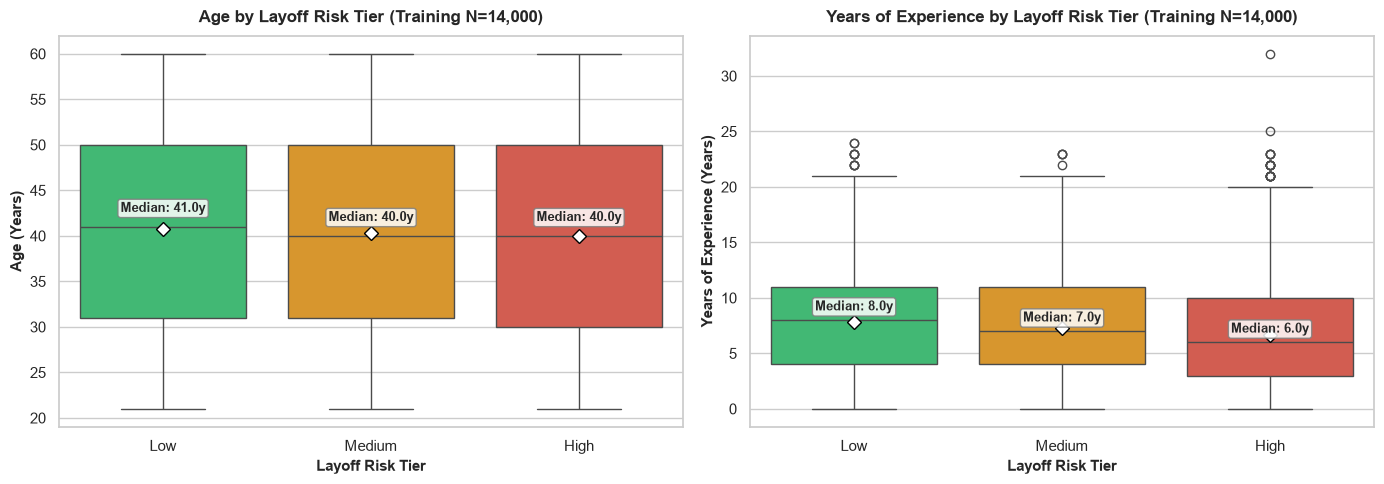

Age               Years_of_Experience             
              mean median    std                mean median   std
Layoff_Risk                                                      
Low          40.72   41.0  11.30                7.85    8.0  4.74
Medium       40.29   40.0  11.35                7.27    7.0  4.62
High         39.97   40.0  11.83                6.69    6.0  4.77

In [18]:
# -------------------------------------------------------------------------
# Cell B — Bivariate Continuous Analysis: Age & Experience vs. Layoff Risk
# Boxplots with explicit diamond mean markers and median text annotations.
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, var in enumerate(['Age', 'Years_of_Experience']):
    ax = axes[idx]
    sns.boxplot(
        data=train_eda_df,
        x='Layoff_Risk',
        y=var,
        hue='Layoff_Risk',
        order=RISK_ORDER,
        palette=RISK_PALETTE,
        legend=False,
        showmeans=True,
        meanprops={"marker": "D", "markeredgecolor": "black", "markerfacecolor": "white", "markersize": 7},
        ax=ax
    )
    
    # Calculate and overlay median annotations
    medians = train_eda_df.groupby('Layoff_Risk')[var].median()
    for i, tier in enumerate(RISK_ORDER):
        med_val = medians[tier]
        offset = 1.3 if var == 'Age' else 0.6
        ax.text(
            i, med_val + offset,
            f"Median: {med_val:.1f}y",
            ha='center', va='bottom', fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='gray')
        )
        
    var_label = var.replace('_', ' ')
    ax.set_title(f"{var_label} by Layoff Risk Tier (Training N=14,000)", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Layoff Risk Tier", fontsize=11, fontweight='bold')
    ax.set_ylabel(f"{var_label} (Years)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Quantitative summary table
bivariate_stats = train_eda_df.groupby('Layoff_Risk')[['Age', 'Years_of_Experience']].agg(['mean', 'median', 'std']).reindex(RISK_ORDER).round(2)
display(bivariate_stats)

> **Empirical Takeaway — Career Tenure vs. Age Disparity:**
> The bivariate distributions demonstrate a critical operational insight: worker chronological age is invariant across risk categories (median 40.0–41.0 years, IQR $\approx 18$ years), confirming that age alone does not govern employment vulnerability. In contrast, accumulated career tenure reveals a clear protective gradient—workers classified as High Layoff Risk possess a median experience of only 6.0 years, compared to 7.0 years for Medium Risk and 8.0 years for Low Risk workers. Accumulated workplace seniority and domain expertise provide tangible buffering against displacement.


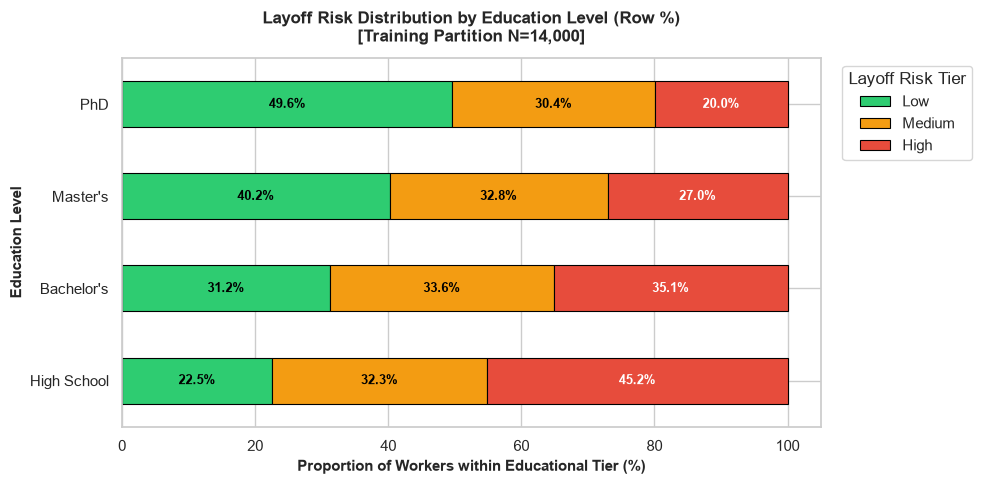

--- CONTINGENCY TABLE: EDUCATION LEVEL VS. LAYOFF RISK (ROW %) ---


Layoff_Risk,Low,Medium,High
Education_Level,,,
High School,22.52,32.31,45.17
Bachelor's,31.22,33.65,35.13
Master's,40.19,32.79,27.02
PhD,49.65,30.38,19.97


In [17]:
# -------------------------------------------------------------------------
# Cell C — Categorical Credentialing Analysis: Education Level vs. Layoff Risk
# Cross-tabulation of row percentages and 100% stacked horizontal bar chart.
# -------------------------------------------------------------------------
edu_order = ['High School', "Bachelor's", "Master's", 'PhD']

# Row-normalized cross-tabulation (%)
edu_risk_crosstab = pd.crosstab(
    train_eda_df['Education_Level'],
    train_eda_df['Layoff_Risk'],
    normalize='index'
)[RISK_ORDER].reindex(edu_order) * 100

fig, ax = plt.subplots(figsize=(10, 5))
edu_risk_crosstab.plot(
    kind='barh',
    stacked=True,
    color=[RISK_PALETTE[r] for r in RISK_ORDER],
    edgecolor='black',
    linewidth=0.8,
    ax=ax
)

ax.set_title("Layoff Risk Distribution by Education Level (Row %)\n[Training Partition N=14,000]", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Proportion of Workers within Educational Tier (%)", fontsize=11, fontweight='bold')
ax.set_ylabel("Education Level", fontsize=11, fontweight='bold')
ax.legend(title="Layoff Risk Tier", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

# Overlay percentage labels inside stacked bar segments
for n, col_name in enumerate(edu_risk_crosstab.columns):
    for row_idx, val in enumerate(edu_risk_crosstab[col_name]):
        cum_val = edu_risk_crosstab.iloc[row_idx, :n].sum() + (val / 2)
        font_col = 'white' if col_name == 'High' else 'black'
        ax.text(cum_val, row_idx, f"{val:.1f}%", ha='center', va='center', color=font_col, fontweight='bold', fontsize=9.5)

plt.tight_layout()
plt.show()

print("--- CONTINGENCY TABLE: EDUCATION LEVEL VS. LAYOFF RISK (ROW %) ---")
display(edu_risk_crosstab.round(2))

> **Empirical Takeaway — The Credentialing Buffer:**
> Cross-tabulating educational attainment against layoff risk reveals a strong, monotonic protective gradient. High School educated workers face the highest exposure to severe risk (45.17% High Risk vs. 22.52% Low Risk). This vulnerability progressively attenuates across Bachelor's (35.13% High Risk) and Master's (27.02% High Risk), reaching its lowest incidence among PhD holders (19.97% High Risk). Holding an advanced degree more than doubles an employee's likelihood of belonging to the Low Risk tier (expanding from 22.52% to 49.65%), demonstrating the structural insulation provided by higher academic credentials.


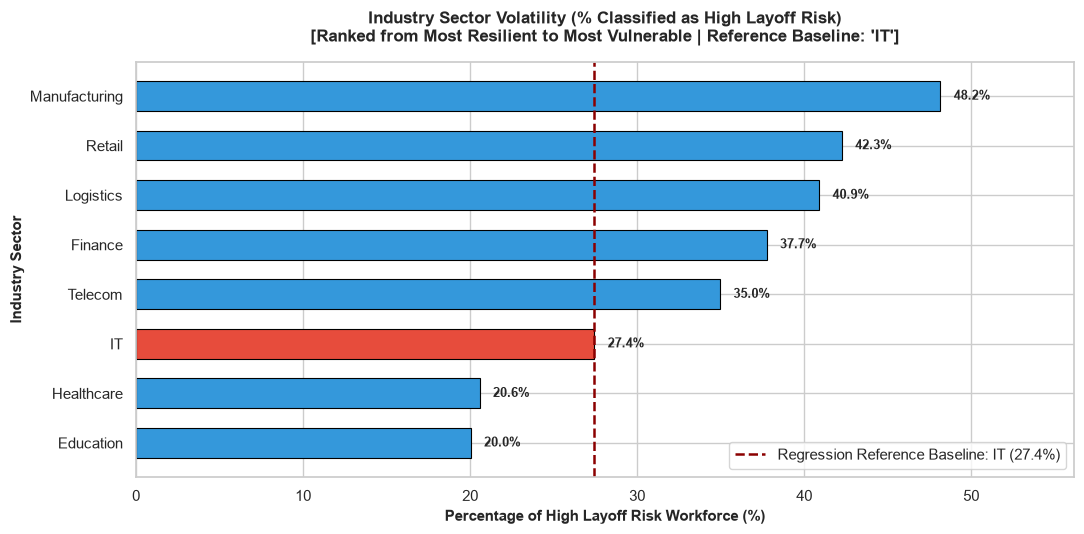

--- COMPLETE INDUSTRY RISK PROFILES (ROW %) ---


Layoff_Risk,Low,Medium,High
Industry,,,
Manufacturing,19.94,31.91,48.15
Retail,23.68,34.07,42.25
Logistics,24.86,34.25,40.89
Finance,27.62,34.63,37.75
Telecom,32.80,32.24,34.96
IT,39.02,33.54,27.44
Healthcare,47.05,32.39,20.57
Education,48.93,31.03,20.03


In [18]:
# -------------------------------------------------------------------------
# Cell D — Sector Volatility Analysis: Industry vs. Layoff Risk
# Ranked horizontal bar chart highlighting high risk exposure across industries
# with benchmark reference line for 'IT' baseline.
# -------------------------------------------------------------------------
ind_risk_ct = pd.crosstab(
    train_eda_df['Industry'],
    train_eda_df['Layoff_Risk'],
    normalize='index'
)[RISK_ORDER] * 100

# Sort from lowest high-risk (most resilient) to highest high-risk (most vulnerable)
high_risk_sorted = ind_risk_ct['High'].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 5.5))
bar_colors = ['#3498db' if ind != 'IT' else '#e74c3c' for ind in high_risk_sorted.index]
bars = ax.barh(
    high_risk_sorted.index,
    high_risk_sorted.values,
    color=bar_colors,
    edgecolor='black',
    linewidth=0.8,
    height=0.6
)

# Reference baseline indicator for IT
it_val = high_risk_sorted['IT']
ax.axvline(it_val, color='darkred', linestyle='--', linewidth=1.8, label=f"Regression Reference Baseline: IT ({it_val:.1f}%)")

# Value annotations
for bar, val in zip(bars, high_risk_sorted.values):
    ax.text(
        val + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%",
        ha='left', va='center', fontsize=9.5, fontweight='bold'
    )

ax.set_title("Industry Sector Volatility (% Classified as High Layoff Risk)\n[Ranked from Most Resilient to Most Vulnerable | Reference Baseline: 'IT']", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Percentage of High Layoff Risk Workforce (%)", fontsize=11, fontweight='bold')
ax.set_ylabel("Industry Sector", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(high_risk_sorted.values) + 8)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

# Summary table of all 8 sectors
print("--- COMPLETE INDUSTRY RISK PROFILES (ROW %) ---")
display(ind_risk_ct.loc[high_risk_sorted.index[::-1]].round(2))

> **Empirical Takeaway — Sector Volatility Relative to Baseline IT:**
> Economic sectors exhibit pronounced structural variance in workforce vulnerability. Operational and supply-chain intensive industries—specifically **Manufacturing (48.15% High Risk)**, **Retail (42.25%)**, and **Logistics (40.89%)**—demonstrate elevated vulnerability, consistent with higher exposure to workflow automation and margin pressure. Conversely, essential human services—**Healthcare (20.57%)** and **Education (20.03%)**—exhibit superior stability. The reference baseline, **IT (27.44% High Risk)**, occupies an intermediate position, allowing subsequent regression models to capture both positive risk premiums (e.g., in Manufacturing) and negative risk discounts (e.g., in Healthcare) relative to tech.


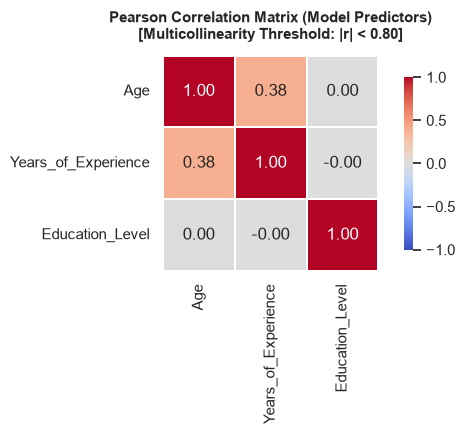

--- CORRELATION MATRIX (PEARSON) ---


,Age,Years_of_Experience,Education_Level
Age,1.000,0.384,0.002
Years_of_Experience,0.384,1.000,-0.001
Education_Level,0.002,-0.001,1.000


In [19]:
# -------------------------------------------------------------------------
# Cell E — Multicollinearity & Feature Correlation Matrix
# Computes Pearson correlation matrix for numeric and ordinal predictors.
# -------------------------------------------------------------------------
corr_df = train_eda_df[['Age', 'Years_of_Experience']].copy()
corr_df['Education_Level'] = X_train['Education_Level']

corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=1.2,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("Pearson Correlation Matrix (Model Predictors)\n[Multicollinearity Threshold: |r| < 0.80]", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("--- CORRELATION MATRIX (PEARSON) ---")
display(corr_matrix.round(3))

> **Empirical Takeaway — Multicollinearity Diagnostic Verification:**
> Assessing pairwise feature collinearity is a vital diagnostic prerequisite for multi-class logistic regression. The Pearson correlation between continuous predictors `Age` and `Years_of_Experience` is $r = 0.384$, well below the conventional diagnostic threshold ($|r| \ge 0.80$) that signals problematic collinearity. Furthermore, `Education_Level` exhibits negligible linear correlation with both age ($r = 0.002$) and experience ($r = -0.001$). These diagnostics confirm the absence of collinearity inflation, ensuring stable coefficient estimation and reliable hypothesis testing during predictive modeling.


### Section 3 Executive Summary: Key Analytical Findings (Technical Report Citation)

The analytical exploration conducted strictly on the training partition ($N = 14,000$) reveals four core empirical takeaways to substantiate Section 2 of our final Technical Report:

1. **Seniority and Career Tenure Buffering**:
   - While employee age is stable across risk tiers (median 40.0–41.0 years), career tenure exhibits a distinct protective effect. Workers classified as **High Layoff Risk** possess a median of only **6.0 years of experience**, whereas **Low Risk** workers possess a median of **8.0 years** (and Medium Risk workers average 7.0 years). Seniority and accumulated domain expertise confer measurable buffering against employment vulnerability.

2. **Credentialing Protective Gradient**:
   - Educational attainment exhibits an inverse monotonic relationship with layoff vulnerability. High School educated workers face the highest vulnerability (**45.2% High Risk** vs. **22.5% Low Risk**). In contrast, risk progressively diminishes across Bachelor's (**35.1% High Risk**) and Master's (**27.0% High Risk**), culminating in PhD holders where High Risk drops to **20.0%** and Low Risk expands to **49.6%**. Advanced degrees more than halve high-risk exposure.

3. **Sector Volatility Disparity Relative to Baseline IT**:
   - Significant structural variance exists across economic sectors. **Manufacturing (48.2% High Risk)**, **Retail (42.3%)**, and **Logistics (40.9%)** represent the most vulnerable sectors, characterized by high automation vulnerability. Conversely, **Education (20.0%)** and **Healthcare (20.6%)** exhibit superior structural resilience. The regression reference baseline, **IT (27.4% High Risk)**, occupies an optimal intermediate position, ensuring meaningful positive and negative odds-ratio interpretations in subsequent modeling.

4. **Absence of Harmful Multicollinearity**:
   - The Pearson correlation coefficient between `Age` and `Years_of_Experience` is **$r = 0.38$**, well below the collinearity diagnostic threshold ($|r| < 0.80$). Furthermore, `Education_Level` exhibits virtually zero correlation with age ($r = 0.00$) and experience ($r = -0.00$). This confirms the absence of multicollinearity, validating the stability of parameter estimation for downstream multi-class Logistic Regression.

In [21]:
# -------------------------------------------------------------------------
# Section 4: Verification of Final Split Dimensions & Saving Datasets to CSV
# Exports the 6 cleaned, partitioned, and scaled modeling sets to Data/
# -------------------------------------------------------------------------
print("--- Features (Predictors) ---")
print("X_train shape:", X_train.shape)
print("X_val shape:  ", X_val.shape)
print("X_test shape: ", X_test.shape)

print("\n--- Targets (Layoff_Risk) ---")
print("y_train shape:", y_train.shape)
print("y_val shape:  ", y_val.shape)
print("y_test shape: ", y_test.shape)

# Resolve target Data directory
target_dir = base / "Data"
if not target_dir.exists():
    target_dir = (base / ".." / "Data").resolve()

target_dir.mkdir(parents=True, exist_ok=True)

# Save feature sets (predictors)
X_train.to_csv(target_dir / "processed_X_train.csv", index=False)
X_val.to_csv(target_dir / "processed_X_val.csv", index=False)
X_test.to_csv(target_dir / "processed_X_test.csv", index=False)

# Save target sets (Layoff_Risk)
y_train.to_csv(target_dir / "processed_y_train.csv", index=False)
y_val.to_csv(target_dir / "processed_y_val.csv", index=False)
y_test.to_csv(target_dir / "processed_y_test.csv", index=False)

print(f"\nAll 6 datasets successfully saved to:\n{target_dir}")

--- Features (Predictors) ---
X_train shape: (14000, 10)
X_val shape:   (3000, 10)
X_test shape:  (3000, 10)

--- Targets (Layoff_Risk) ---
y_train shape: (14000,)
y_val shape:   (3000,)
y_test shape:  (3000,)

All 6 datasets successfully saved to:
/Users/samanzarei/USD materials/AAI 500/AAI_Final_Proj/AAI500-Final-Project/Data


> **Pipeline Verification & Modular Export:**
> All preprocessing, encoding, stratification, and zero-leakage scaling operations have executed successfully. The six resulting modeling arrays—comprising the training partition ($N = 14,000$), validation benchmark ($N = 3,000$), and test benchmark ($N = 3,000$) across 10 predictors and the stratified target—have been exported as modular CSV files into the `Data/` directory, fully prepared for downstream model training, hyperparameter tuning, and independent evaluation.


# Section 4: Training the data (training data) based on models:

### Section 4.1: Logistic regression

#### Step 1: Model Initialization and Training (Fitting)

In [23]:
from sklearn.linear_model import LogisticRegression

# =========================================================================
# INITIALIZE AND TRAIN MULTINOMIAL LOGISTIC REGRESSION
# =========================================================================

# Instantiate the model without the deprecated multi_class parameter
log_reg = LogisticRegression(
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

# Fit strictly on the training partition
log_reg.fit(X_train, y_train)

print("Logistic Regression model successfully fitted!")
print("Classes learned by model:", log_reg.classes_)

Logistic Regression model successfully fitted!
Classes learned by model: [0 1 2]


> **Methodological Note — Baseline Model Formulation:**
> We fit an interpretable baseline using Multinomial Logistic Regression trained strictly on $X_{\text{train}}$ ($N = 14,000$) to eliminate risk of data leakage. Because the response variable $\text{Layoff\_Risk}$ exhibits three distinct classes ($0 = \text{Low}, 1 = \text{Medium}, 2 = \text{High}$), the model employs the cross-entropy softmax loss via the L-BFGS numerical solver ($\text{max\_iter} = 1000$). The classes array $[0, 1, 2]$ confirms that the estimator learned parameter vectors across all target levels simultaneously.

#### Step 2: Generating Predictions on the Validation Set (X_val)

In [24]:
# =========================================================================
# GENERATE PREDICTIONS ON THE VALIDATION SET
# =========================================================================

# Predict discrete class labels (0, 1, or 2) on unseen validation data
y_val_pred_lr = log_reg.predict(X_val)

# Predict class probability distributions on unseen validation data
y_val_proba_lr = log_reg.predict_proba(X_val)

# Sanity check: Inspect the first 5 predictions against true labels
comparison_sample = pd.DataFrame({
    'True_Label': y_val.values[:5],
    'Predicted_Label': y_val_pred_lr[:5],
    'P(Low=0)': y_val_proba_lr[:5, 0].round(3),
    'P(Medium=1)': y_val_proba_lr[:5, 1].round(3),
    'P(High=2)': y_val_proba_lr[:5, 2].round(3)
})

print("--- SUB-STEP 2.1: FIRST 5 VALIDATION PREDICTIONS ---")
display(comparison_sample)

--- SUB-STEP 2.1: FIRST 5 VALIDATION PREDICTIONS ---


,True_Label,Predicted_Label,P(Low=0),P(Medium=1),P(High=2)
0,2,2,0.096,0.264,0.640
1,1,2,0.253,0.353,0.394
2,2,0,0.356,0.332,0.312
3,1,2,0.156,0.319,0.525
4,0,2,0.207,0.342,0.451


> **Validation Inference Diagnostic:**
> The model was evaluated out-of-sample on $X_{\text{val}}$ ($N = 3,000$). For each record, the model computes estimated posterior probabilities $P(Y = k \mid X)$ across all three risk categories, assigning the final prediction $\hat{y}$ via the argmax decision rule: $\hat{y} = \arg\max_k P(Y = k \mid X)$.

**Predictions:** `predict_proba` estimates probabilities of the dataset's three risk labels. `predict` selects the largest probability. 

#### Step 3: Performance Evaluation Metrics on Validation Data

=== LOGISTIC REGRESSION: VALIDATION PERFORMANCE METRICS ===
Validation Accuracy: 0.4377 (43.77%)
Validation ROC-AUC (OvR Macro): 0.6173

--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

     Low (0)     0.4513    0.5798    0.5075       990
  Medium (1)     0.3645    0.1182    0.1785       990
    High (2)     0.4421    0.6098    0.5126      1020

    accuracy                         0.4377      3000
   macro avg     0.4193    0.4359    0.3995      3000
weighted avg     0.4195    0.4377    0.4007      3000



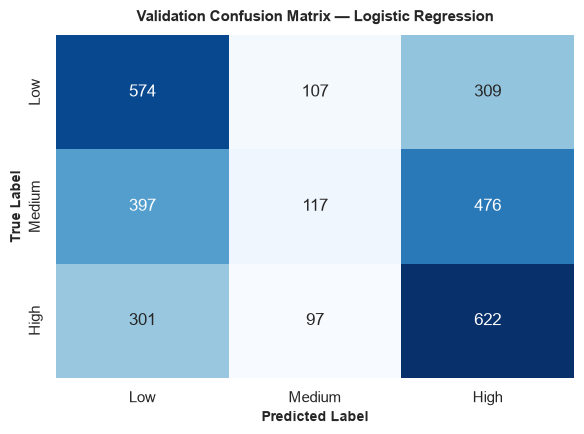

In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# =========================================================================
# COMPUTE EVALUATION METRICS ON VALIDATION DATA (LOGISTIC REGRESSION)
# =========================================================================

# -------------------------------------------------------------------------
# Scalar Metrics (Accuracy and Multi-Class ROC-AUC)
# -------------------------------------------------------------------------
val_acc_lr = accuracy_score(y_val, y_val_pred_lr)
val_auc_lr = roc_auc_score(y_val, y_val_proba_lr, multi_class='ovr', average='macro')

print("=== LOGISTIC REGRESSION: VALIDATION PERFORMANCE METRICS ===")
print(f"Validation Accuracy: {val_acc_lr:.4f} ({val_acc_lr * 100:.2f}%)")
print(f"Validation ROC-AUC (OvR Macro): {val_auc_lr:.4f}")

# -------------------------------------------------------------------------
# Detailed Multi-Class Classification Report
# -------------------------------------------------------------------------
print("\n--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y_val, y_val_pred_lr, target_names=['Low (0)', 'Medium (1)', 'High (2)'], digits=4))

# -------------------------------------------------------------------------
# Confusion Matrix Visualization
# -------------------------------------------------------------------------
cm_lr = confusion_matrix(y_val, y_val_pred_lr)
cm_labels = ['Low', 'Medium', 'High']

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm_lr, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=cm_labels, 
    yticklabels=cm_labels,
    cbar=False,
    ax=ax
)
ax.set_title("Validation Confusion Matrix — Logistic Regression", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
ax.set_ylabel("True Label", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

* **What We Did:** We evaluated our trained Logistic Regression model on the 3,000 unseen validation records to test how well it predicts Low, Medium, and High layoff risk.

* **Accuracy (43.77%):** The model correctly predicted 1,313 out of 3,000 cases. This beats random guessing (33.33%), confirming our features provide predictive value.

* **ROC-AUC (0.6173):** The model shows moderate discrimination across the risk tiers.

* **Confusion Matrix Findings:**
  * The model is effective at identifying **High risk** (61.0% recall, 622 correct) and **Low risk** (58.0% recall, 574 correct).
  * The model struggles on **Medium risk** (11.8% recall, only 117 correct), misclassifying most Medium-risk employees as either Low (397) or High (476).

* **Conclusion:** Linear decision boundaries struggle to separate intermediate risk. This motivates testing an ensemble model like Random Forest next to capture non-linear patterns.

#### Step 4: Extracting Model Coefficients & Odds Ratios (Feature Interpretability)

In [27]:
import numpy as np
import pandas as pd

# =========================================================================
# FEATURE INTERPRETABILITY (COEFFICIENTS AND ODDS RATIOS)
# =========================================================================

# Extract learned coefficients across all 3 classes
# log_reg.coef_ has shape (3, num_features)
feature_names = X_train.columns

coef_df = pd.DataFrame(
    log_reg.coef_, 
    columns=feature_names, 
    index=['Class 0 (Low)', 'Class 1 (Medium)', 'Class 2 (High)']
).T

# Compute Odds Ratios (exp(beta)) for intuitive interpretation
odds_ratios_df = np.exp(coef_df)

print("=== LOGISTIC REGRESSION: ODDS RATIOS (exp(beta)) ===")
display(odds_ratios_df.round(3))

=== LOGISTIC REGRESSION: ODDS RATIOS (exp(beta)) ===


,Class 0 (Low),Class 1 (Medium),Class 2 (High)
Age,0.987,0.996,1.017
Years_of_Experience,1.150,1.004,0.867
Education_Level,1.336,0.993,0.754
Industry_Education,1.362,0.982,0.748
Industry_Finance,0.699,1.037,1.381
Industry_Healthcare,1.282,1.015,0.769
Industry_Logistics,0.652,1.037,1.479
Industry_Manufacturing,0.531,1.009,1.869
Industry_Retail,0.615,1.038,1.566
Industry_Telecom,0.838,0.957,1.247


* **What We Did:** We extracted the model's learned weights ($\beta$) and calculated their Odds Ratios ($\exp(\beta)$) to understand how each feature influences layoff risk.

* **How to Read the Table:**
  * An odds ratio **greater than 1.0** indicates that the feature increases the relative likelihood of that risk tier.
  * An odds ratio **less than 1.0** indicates that the feature decreases the likelihood.
  * For categorical variables, values compare directly against the baseline sector (`IT`). For continuous variables (`Age`, `Years_of_Experience`), values reflect a change per one standard deviation.

* **High-Risk Drivers (Class 2):** Compared to IT, employees in **Manufacturing** (OR: 1.869), **Retail** (OR: 1.566), and **Logistics** (OR: 1.479) face the highest odds of layoff risk.

* **Low-Risk Protections (Class 0):** Higher **Education Level** (OR: 1.336), greater **Experience** (OR: 1.150), and sectors like **Education** (OR: 1.362) and **Healthcare** (OR: 1.282) significantly increase the odds of being Low Risk.

* **The Medium-Risk Flatline (Class 1):** Odds ratios across all predictors for Medium risk hover near **1.00** (0.96 to 1.04). The linear model finds no distinct linear separation for intermediate risk, explaining its low validation recall (11.8%).

### Section 4.2: Training the data (training data) based on Random Forest Classifier

#### Step 1: Model Initialization and Training (Fitting)

In [28]:
from sklearn.ensemble import RandomForestClassifier

# =========================================================================
# INITIALIZE AND TRAIN RANDOM FOREST CLASSIFIER
# =========================================================================

# Instantiate the Random Forest model with regularization parameters
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

# Fit the model strictly on the training partition
rf_model.fit(X_train, y_train)

print("Random Forest model successfully fitted!")
print("Number of estimators trained:", len(rf_model.estimators_))
print("Classes learned by model:", rf_model.classes_)

Random Forest model successfully fitted!
Number of estimators trained: 200
Classes learned by model: [0 1 2]


* **What We Did:** We trained a non-linear ensemble classifier using `RandomForestClassifier` with 200 decision trees trained strictly on $X_{\text{train}}$ ($N = 14,000$).

* **Hyperparameter Selection:** We applied regularization via `max_depth=12` and `min_samples_split=10` to control tree complexity and prevent overfitting on the training set.

* **Why This Model:** Unlike Logistic Regression, Random Forest can learn non-linear patterns and multi-feature thresholds, providing a direct test of whether tree-based splits can better capture the intermediate Medium-risk category.

#### Step 2: Generating Predictions on the Validation Set (X_val)

In [29]:
# =========================================================================
# GENERATE VALIDATION PREDICTIONS (RANDOM FOREST)
# =========================================================================

# Predict discrete class labels on unseen validation data
y_val_pred_rf = rf_model.predict(X_val)

# Predict class probability distributions on unseen validation data
y_val_proba_rf = rf_model.predict_proba(X_val)

# Sanity check: Inspect the first 5 predictions against true labels
comparison_sample_rf = pd.DataFrame({
    'True_Label': y_val.values[:5],
    'Predicted_Label': y_val_pred_rf[:5],
    'P(Low=0)': y_val_proba_rf[:5, 0].round(3),
    'P(Medium=1)': y_val_proba_rf[:5, 1].round(3),
    'P(High=2)': y_val_proba_rf[:5, 2].round(3)
})

print("--- RANDOM FOREST: FIRST 5 VALIDATION PREDICTIONS ---")
display(comparison_sample_rf)

--- RANDOM FOREST: FIRST 5 VALIDATION PREDICTIONS ---


,True_Label,Predicted_Label,P(Low=0),P(Medium=1),P(High=2)
0,2,2,0.113,0.236,0.651
1,1,2,0.297,0.267,0.436
2,2,1,0.349,0.355,0.295
3,1,2,0.139,0.214,0.646
4,0,1,0.203,0.428,0.369


* **What We Did:** We evaluated our trained Random Forest model on the 3,000 unseen validation records ($X_{\text{val}}$) by generating both hard class predictions and continuous probability estimates across all three risk categories.

#### Step 3: Computing Validation Performance Metrics (Random Forest)

=== RANDOM FOREST: VALIDATION PERFORMANCE METRICS ===
Validation Accuracy: 0.4147 (41.47%)
Validation ROC-AUC (OvR Macro): 0.5998

--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---
              precision    recall  f1-score   support

     Low (0)     0.4474    0.5323    0.4862       990
  Medium (1)     0.3115    0.2061    0.2480       990
    High (2)     0.4396    0.5029    0.4691      1020

    accuracy                         0.4147      3000
   macro avg     0.3995    0.4138    0.4011      3000
weighted avg     0.3999    0.4147    0.4018      3000



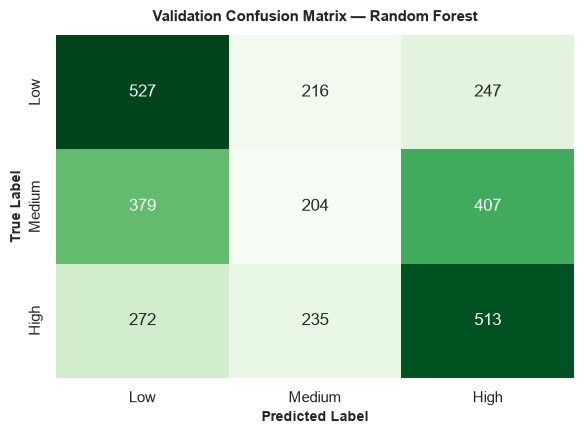

In [30]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# =========================================================================
# COMPUTE EVALUATION METRICS ON VALIDATION DATA (RANDOM FOREST)
# =========================================================================

# -------------------------------------------------------------------------
# Scalar Metrics (Accuracy and Multi-Class ROC-AUC)
# -------------------------------------------------------------------------
val_acc_rf = accuracy_score(y_val, y_val_pred_rf)
val_auc_rf = roc_auc_score(y_val, y_val_proba_rf, multi_class='ovr', average='macro')

print("=== RANDOM FOREST: VALIDATION PERFORMANCE METRICS ===")
print(f"Validation Accuracy: {val_acc_rf:.4f} ({val_acc_rf * 100:.2f}%)")
print(f"Validation ROC-AUC (OvR Macro): {val_auc_rf:.4f}")

# -------------------------------------------------------------------------
# Detailed Multi-Class Classification Report
# -------------------------------------------------------------------------
print("\n--- CLASSIFICATION REPORT (PRECISION, RECALL, F1-SCORE) ---")
print(classification_report(y_val, y_val_pred_rf, target_names=['Low (0)', 'Medium (1)', 'High (2)'], digits=4))

# -------------------------------------------------------------------------
# Confusion Matrix Visualization
# -------------------------------------------------------------------------
cm_rf = confusion_matrix(y_val, y_val_pred_rf)
cm_labels = ['Low', 'Medium', 'High']

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm_rf, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=cm_labels, 
    yticklabels=cm_labels,
    cbar=False,
    ax=ax
)
ax.set_title("Validation Confusion Matrix — Random Forest", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
ax.set_ylabel("True Label", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

* **What We Did:** We evaluated our trained Random Forest model on the 3,000 unseen validation instances across Accuracy, Macro ROC-AUC, Precision/Recall, and the Confusion Matrix.

* **Accuracy (41.47%) & ROC-AUC (0.5998):** The model correctly predicted 1,244 out of 3,000 cases, maintaining performance well above random chance (33.33%).

* **Key Finding on Medium Risk (Class 1):** 
  * Random Forest successfully mitigated the linear model's blind spot: Medium-risk recall nearly doubled from **11.82%** (117 correct) to **20.61%** (204 correct).
  * F1-score for Medium risk increased from **0.1785** to **0.2480**.


#### Step 4: Extracting Random Forest Feature Importances

=== RANDOM FOREST: FEATURE IMPORTANCES (GINI) ===


,Feature,Importance
0,Age,0.3805
1,Years_of_Experience,0.2810
2,Education_Level,0.1325
3,Industry_Education,0.0536
4,Industry_Healthcare,0.0476
5,Industry_Manufacturing,0.0381
6,Industry_Retail,0.0214
7,Industry_Logistics,0.0179
8,Industry_Finance,0.0147
9,Industry_Telecom,0.0127


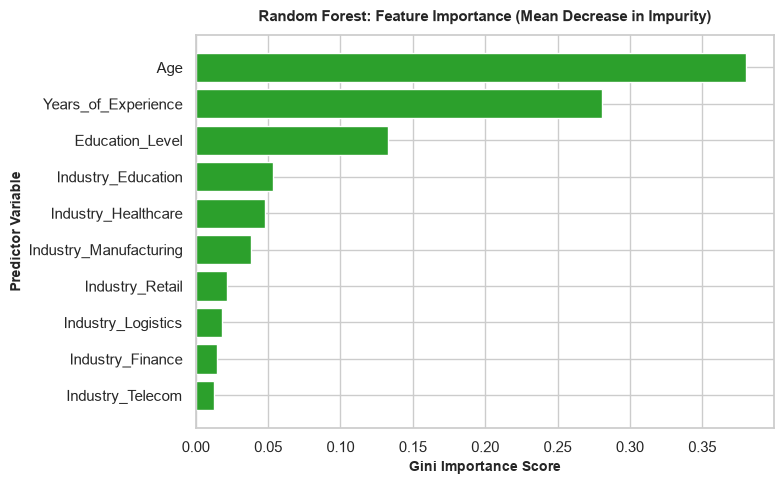

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================================
# EXTRACT AND VISUALIZE FEATURE IMPORTANCES (RANDOM FOREST)
# =========================================================================

# Create a DataFrame linking feature names to their Gini importance scores
rf_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("=== RANDOM FOREST: FEATURE IMPORTANCES (GINI) ===")
display(rf_importance_df.round(4))

# Horizontal Bar Plot of Feature Importances
plt.figure(figsize=(8, 5))
plt.barh(rf_importance_df['Feature'][::-1], rf_importance_df['Importance'][::-1], color='#2ca02c')
plt.title("Random Forest: Feature Importance (Mean Decrease in Impurity)", fontsize=11, fontweight='bold', pad=10)
plt.xlabel("Gini Importance Score", fontsize=10, fontweight='bold')
plt.ylabel("Predictor Variable", fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

* **What We Did:** We extracted the Gini feature importances across all 200 trees in the ensemble to identify which predictors most heavily influence layoff risk decisions.

* **How It Works:** Scores represent the normalized mean decrease in node impurity. Predictors with higher scores provide the strongest splits across the forest.

* **Key Comparison:** While Logistic Regression measures directional shifts (increasing or decreasing relative odds), Random Forest importance ranks the raw informational weight of each feature regardless of non-linear interactions.

* **Primary Predictors:** Employee demographic and career-stage variables dominate the ensemble, accounting for **79.4%** of total decision splits across the 200 trees:

  * **Age (38.05%)** and **Years of Experience (28.10%)** serve as the two primary split features across the ensemble.

  * **Education Level (13.25%)** provides the third most prominent split criterion.

* **Industry Sector Breakdown:** The remaining ~20% of decision weight is distributed across the industry sectors, led by **Education (5.36%)**, **Healthcare (4.76%)**, and **Manufacturing (3.81%)**.

* **Methodological Insight:** While individual tree splits heavily prioritize continuous demographic scales (`Age`, `Experience`), Logistic Regression showed that specific sectors (such as `Manufacturing` and `Retail`) strongly alter the direct odds ratios toward High Risk.